# 04 - Modelagem e Validação

**Objetivo:** Comparar classificadores e escolher o melhor modelo.


In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

OUTPUT_DIR = './pipeline_output/'
X_train = np.load(OUTPUT_DIR + 'X_train_processed.npy')
X_val = np.load(OUTPUT_DIR + 'X_val_processed.npy')
y_train = np.load(OUTPUT_DIR + 'y_train.npy')
y_val = np.load(OUTPUT_DIR + 'y_val.npy')

print('Treino:', X_train.shape)
print('Validação:', X_val.shape)


Treino: (2505, 9)
Validação: (627, 9)


## 1. Definição dos Modelos


In [16]:
models = {
    'Dummy (most frequent)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'LDA': LinearDiscriminantAnalysis(),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'SVM (Linear)': SVC(kernel='linear', random_state=42),
    'SVM (RBF)': SVC(kernel='rbf', random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest (100)': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

print('Modelos:', list(models.keys()))


Modelos: ['Dummy (most frequent)', 'Logistic Regression', 'LDA', 'KNN (k=5)', 'SVM (Linear)', 'SVM (RBF)', 'Decision Tree', 'Random Forest (100)']


## 2. Validação Cruzada Estratificada


In [17]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    acc_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    f1_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    results.append({
        'model': name,
        'acc_mean': acc_scores.mean(),
        'acc_std': acc_scores.std(),
        'f1_mean': f1_scores.mean(),
        'f1_std': f1_scores.std(),
    })
    print(f"{name:25s} | acc={acc_scores.mean():.4f} +/- {acc_scores.std():.4f} | f1={f1_scores.mean():.4f} +/- {f1_scores.std():.4f}")


Dummy (most frequent)     | acc=0.3441 +/- 0.0014 | f1=0.1707 +/- 0.0005
Logistic Regression       | acc=0.6491 +/- 0.0201 | f1=0.6444 +/- 0.0191
LDA                       | acc=0.6323 +/- 0.0224 | f1=0.6338 +/- 0.0211
KNN (k=5)                 | acc=0.6144 +/- 0.0224 | f1=0.6109 +/- 0.0210
SVM (Linear)              | acc=0.6463 +/- 0.0209 | f1=0.6455 +/- 0.0202
SVM (RBF)                 | acc=0.6527 +/- 0.0258 | f1=0.6470 +/- 0.0246
Decision Tree             | acc=0.5740 +/- 0.0288 | f1=0.5702 +/- 0.0280
Random Forest (100)       | acc=0.6359 +/- 0.0278 | f1=0.6324 +/- 0.0257


## 3. Tabela Comparativa


                model  acc_mean  f1_mean
            SVM (RBF)    0.6527   0.6470
  Logistic Regression    0.6491   0.6444
         SVM (Linear)    0.6463   0.6455
  Random Forest (100)    0.6359   0.6324
                  LDA    0.6323   0.6338
            KNN (k=5)    0.6144   0.6109
        Decision Tree    0.5740   0.5702
Dummy (most frequent)    0.3441   0.1707


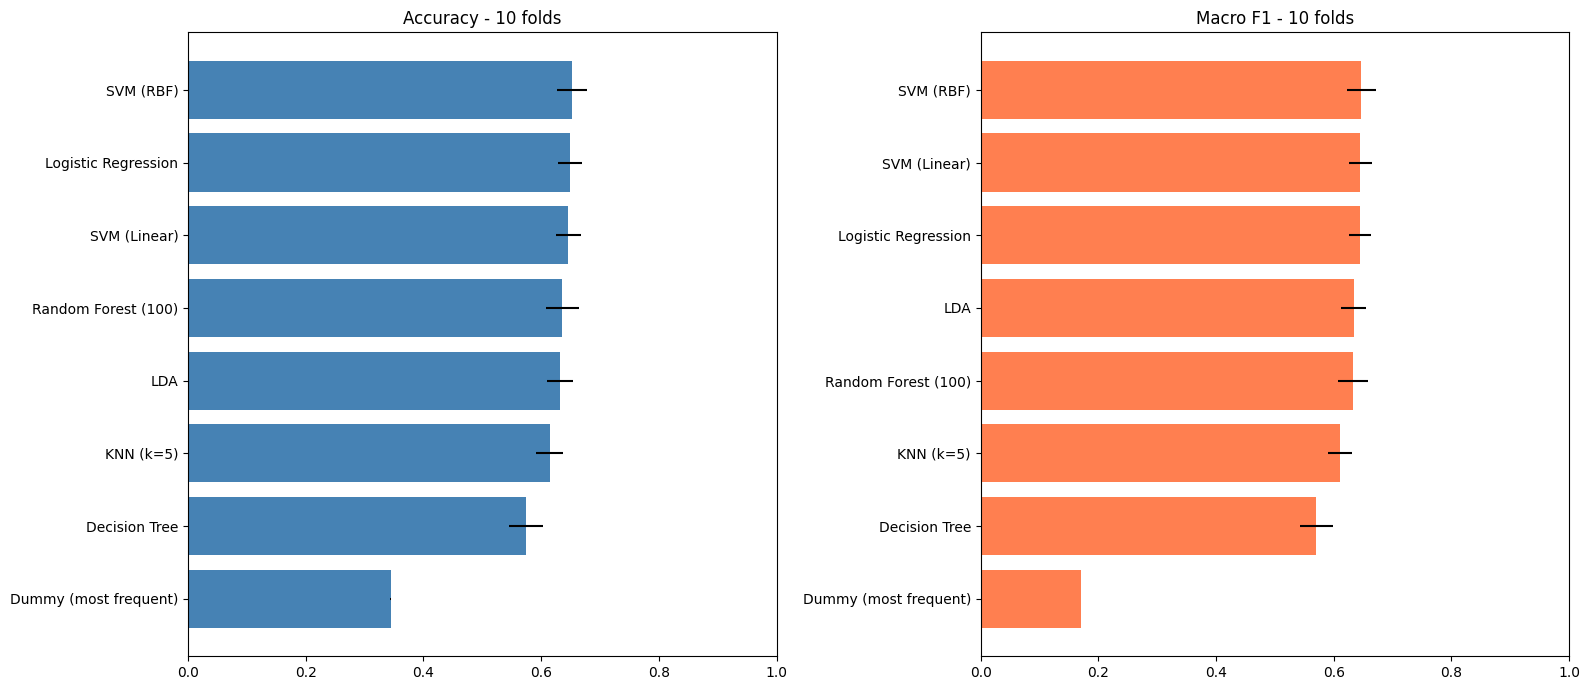

In [18]:
results_df = pd.DataFrame(results).sort_values('acc_mean', ascending=False).reset_index(drop=True)
print(results_df[['model', 'acc_mean', 'f1_mean']].round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
acc_sorted = results_df.sort_values('acc_mean')
f1_sorted = results_df.sort_values('f1_mean')

axes[0].barh(acc_sorted['model'], acc_sorted['acc_mean'], xerr=acc_sorted['acc_std'], color='steelblue')
axes[0].set_title('Accuracy - 10 folds')
axes[0].set_xlim(0, 1)

axes[1].barh(f1_sorted['model'], f1_sorted['f1_mean'], xerr=f1_sorted['f1_std'], color='coral')
axes[1].set_title('Macro F1 - 10 folds')
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()


## 4. Avaliação no Holdout


In [19]:
top3 = results_df.head(3)['model'].tolist()
holdout_rows = []

for name in top3:
    model = models[name]
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    holdout_rows.append({
        'model': name,
        'acc_holdout': accuracy_score(y_val, pred),
        'f1_holdout': f1_score(y_val, pred, average='macro'),
    })
    print(name, holdout_rows[-1])

holdout_df = pd.DataFrame(holdout_rows)
print('\n', holdout_df.round(4).to_string(index=False))


SVM (RBF) {'model': 'SVM (RBF)', 'acc_holdout': 0.6762360446570973, 'f1_holdout': 0.6727134600453649}
Logistic Regression {'model': 'Logistic Regression', 'acc_holdout': 0.6666666666666666, 'f1_holdout': 0.66215322255899}
SVM (Linear) {'model': 'SVM (Linear)', 'acc_holdout': 0.6570972886762361, 'f1_holdout': 0.6538507974151423}

               model  acc_holdout  f1_holdout
          SVM (RBF)       0.6762      0.6727
Logistic Regression       0.6667      0.6622
       SVM (Linear)       0.6571      0.6539


## 5. Matriz de Confusão do Melhor Modelo


Melhor modelo: SVM (RBF)
              precision    recall  f1-score   support

           1       0.74      0.80      0.77       216
           2       0.56      0.56      0.56       201
           3       0.72      0.67      0.69       210

    accuracy                           0.68       627
   macro avg       0.67      0.67      0.67       627
weighted avg       0.68      0.68      0.68       627



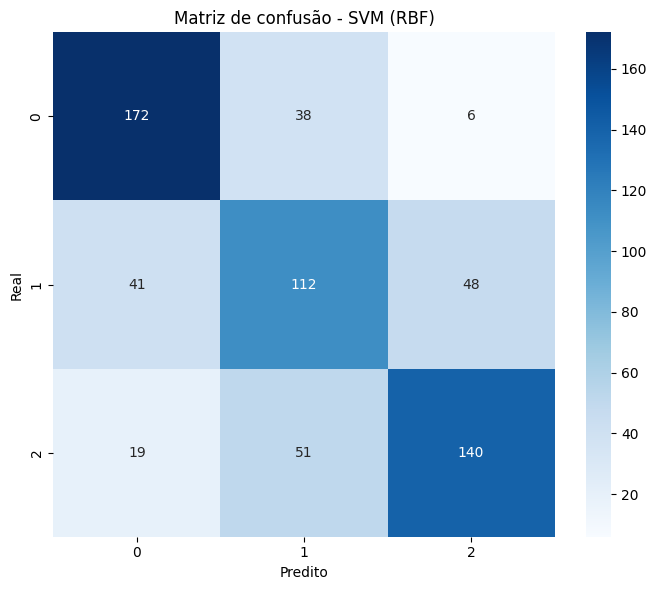

In [20]:
best_model_name = results_df.iloc[0]['model']
best_model = models[best_model_name]
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_val)

cm = confusion_matrix(y_val, y_pred)
print('Melhor modelo:', best_model_name)
print(classification_report(y_val, y_pred))

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set_title(f'Matriz de confusão - {best_model_name}')
ax.set_xlabel('Predito')
ax.set_ylabel('Real')
plt.tight_layout()
plt.show()


## 6. Persistência dos Resultados


In [21]:
results_df.to_csv(OUTPUT_DIR + 'model_comparison.csv', index=False)
with open(OUTPUT_DIR + 'best_model_name.txt', 'w', encoding='utf-8') as f:
    f.write(best_model_name)

print('Salvo:', OUTPUT_DIR + 'model_comparison.csv')
print('Salvo:', OUTPUT_DIR + 'best_model_name.txt')


Salvo: ./pipeline_output/model_comparison.csv
Salvo: ./pipeline_output/best_model_name.txt


## 7. Resumo

- Compare accuracy e macro F1
- Veja estabilidade entre folds
- Use `best_model_name.txt` no notebook 05


In [22]:
print('=' * 60)
print('RESUMO DA MODELAGEM')
print('=' * 60)
print('Melhor modelo:', best_model_name)
print('Próximo passo: Notebook 05 - Modelo final e predição em app')
print('=' * 60)


RESUMO DA MODELAGEM
Melhor modelo: SVM (RBF)
Próximo passo: Notebook 05 - Modelo final e predição em app
